## Laplace's equation in 2D

The laplace equation are basically a equilibrium diffusion solution (so no time derivative), we calculate the equilibrium state of a body based on boundary conditions.

$$\frac{\partial^2 p}{\partial x^2} + \frac{\partial^2 p}{\partial y^2} = 0$$

We discretize the 2 second order derivatives with central-difference schemes. Than our idea, instead of solving for time t, we solve for $p^n_{i, j}$. In theory if we make the number of iterations tend to infinite, we get the final solution, to do so we evaluate convergence of the solution.

OBS: using 2 central-difference schemes (in x and y) is know as using five-point difference operator

We consider boundary conditions in our solutions equations:

$p=0$ at $x=0$

$p=y$ at $x=2$

$\frac{\partial p}{\partial y}=0$ at $y=0, \ 1$

For later comparison the analytical solution is:
$$p(x,y)=\frac{x}{4}-4\sum_{n=1,odd}^{\infty}\frac{1}{(n\pi)^2\sinh2n\pi}\sinh n\pi x\cos n\pi y$$


In [11]:
import numpy as np
from matplotlib import pyplot as plt, cm

In [24]:
#space discretization
nx = 41
ny = 41
dx = 2 / (nx - 1)
dy = 1 / (ny - 1)

x = np.linspace(0, 2, nx)
y = np.linspace(0, 1, ny)

#solution parameters
crit = 1e-4

#'inital' condition
p = np.zeros((nx, ny))
p[:, -1] = y


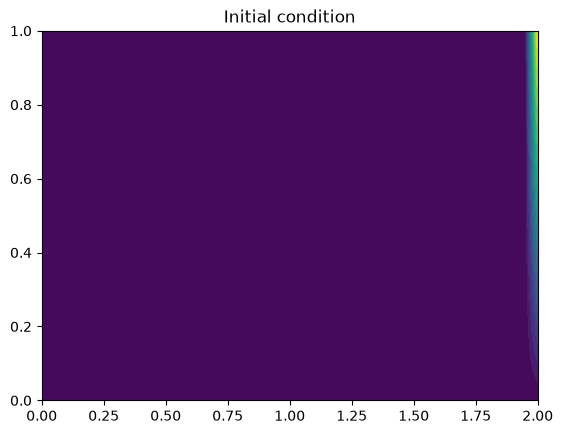

In [25]:
#plot initial condition
fig, ax = plt.subplots()
ax.set_title('Initial condition')
contour = ax.contourf(x, y, p, levels= 20, cmap=cm.viridis)

In [ ]:
#solution loop
err = 1
its = 0

p_iterations:list = []

while err > crit:
    p0 = p.copy()
    p_iterations.append(p0)
    
    #update interior points
    p[1:-1, 1:-1] = (dy**2 * (p0[2:, 1:-1] + p0[:-2, 1:-1]) + dx**2 * (p0[1:-1, 2:] + p0[1:-1, :-2]))/(2*(dx**2 + dy**2))
    
    ##boundary conditions
    p[:, 0] = 0  # p = 0 @ x = 0
    p[:, -1] = y  # p = y @ x = 2
    p[0, :] = p[1, :]  # dp/dy = 0 @ y = 0
    p[-1, :] = p[-2, :]  # dp/dy = 0 @ y = 1
    its += 1
    
    err = np.sum(np.abs(p - p0))

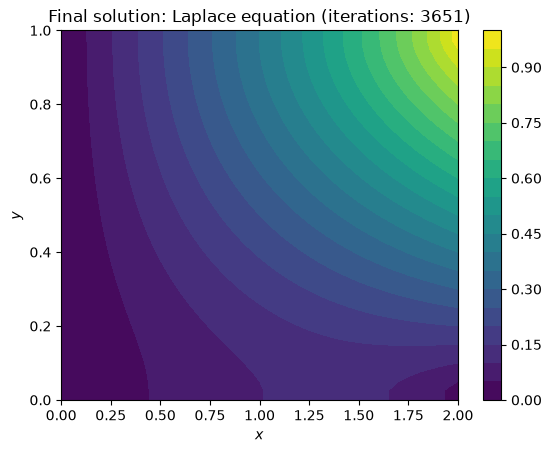

In [30]:
fig, ax = plt.subplots()
ax.set_title(f'Final solution: Laplace equation (iterations: {its})')
ax.set_xlabel('$x$')
ax.set_ylabel('$y$')
contour = ax.contourf(x, y, p, levels= 20, cmap=cm.viridis)
colorbar = fig.colorbar(contour)
